### To Build Deep Learning Model Pipeline we have 2 Libraries:

1. Tensorflow - very old library -> need to write every function -> lengthy codes.
2. Keras 2.0 - is built on top of tensorflow. Dependent on Tensorflow.
3. Keras 3.0 - is independent of Tesorflow.

In [ ]:
import tensorflow as tf #tensorflow v.1

In [ ]:
from tensorflow import keras #Keras 2.0

In [ ]:
import keras #keras 3.0

## ================================================================

## 1. Installing Keras 

In [1]:
!pip install keras

     ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
     - -------------------------------------- 0.1/2.1 MB 1.7 MB/s eta 0:00:02
     --------- ------------------------------ 0.5/2.1 MB 5.1 MB/s eta 0:00:01
     -------------------------- ------------- 1.3/2.1 MB 9.4 MB/s eta 0:00:01
     ---------------------------------------- 2.1/2.1 MB 11.9 MB/s eta 0:00:00
     ---------------------------------------- 0.0/433.7 kB ? eta -:--:--
     ------------------------------------- 433.7/433.7 kB 26.5 MB/s eta 0:00:00
     ---------------------------------------- 0.0/548.0 kB ? eta -:--:--
     ------------------------------------- 548.0/548.0 kB 35.9 MB/s eta 0:00:00
     ---------------------------------------- 0.0/310.7 kB ? eta -:--:--
     ---------------------------------------- 310.7/310.7 kB ? eta 0:00:00
     ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
     ------ --------------------------------- 0.5/3.2 MB 34.1 MB/s eta 0:00:01
     ------ 


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!pip install tensorflow


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## ===============================================================

## Let's build our 1st Artificial Deep Neural Network(ANN)

##  1. Import Necessary Libraries

In [47]:
import keras
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## 2. Data Collection

In [9]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

## 3. Data Understanding

In [10]:
X_train.shape,y_train.shape

((60000, 28, 28), (60000,))

In [11]:
X_test.shape,y_test.shape

((10000, 28, 28), (10000,))

In [12]:
assert X_train.shape == (60000, 28, 28)
assert X_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_test.shape == (10000,)

## 3.1 Let's see how one image Looks like

In [18]:
pd.set_option('display.max_columns', 30)

In [19]:
pd.DataFrame(X_train[10000])

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,29,150,195,254,255,254,176,193,150,96,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,48,166,224,253,253,234,196,253,253,253,253,233,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,93,244,249,253,187,46,10,8,4,10,194,253,253,233,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,107,253,253,230,48,0,0,0,0,0,192,253,253,156,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,3,20,20,15,0,0,0,0,0,43,224,253,245,74,0,0,0,0,0,0,0,0,0


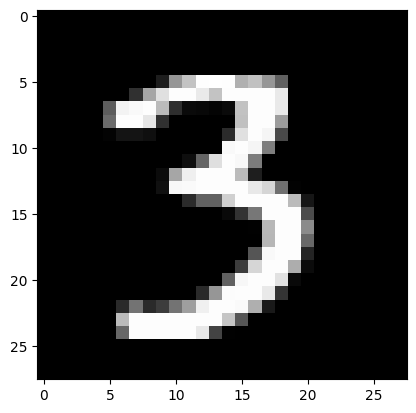

In [21]:
plt.imshow(X_train[10000], cmap = 'gray')

## 4. Data Preparation

### Let's Normalize this for Faster Processing

In [25]:
X_train.min(),X_train.max()

(np.float64(0.0), np.float64(1.0))

In [26]:
X_test.min(),X_test.max()

(np.float64(0.0), np.float64(1.0))

In [27]:
X_train = X_train/255.0
X_test  = X_test/255.0

In [28]:
X_train.min(),X_train.max()

(np.float64(0.0), np.float64(0.00392156862745098))

In [29]:
X_test.min(),X_test.max()

(np.float64(0.0), np.float64(0.00392156862745098))

## 5. Model Building

In [31]:
from keras.models import Sequential
from keras.layers import Flatten,Dense

In [37]:
#INPUT LAYER - 784pixel
model = Sequential()
model.add(layer = Flatten())
model.add(Dense(units = 100,activation = 'relu'))
model.add(Dense(units = 100,activation = 'relu'))
model.add(Dense(units = 10,activation = 'softmax'))
#model.summary()

In [38]:
model.compile(optimizer = 'rmsprop', loss = "sparse_categorical_crossentropy",metrics = ["sparse_categorical_accuracy"])

## 6. Model Training || 7. Model Testing || 8. Model Evaluation

In [39]:
model.fit(x = X_train,y = y_train, batch_size=32,epochs=10,validation_data = (X_test,y_test) )

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 1.2871 - sparse_categorical_accuracy: 0.5878 - val_loss: 0.6343 - val_sparse_categorical_accuracy: 0.8023
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.5130 - sparse_categorical_accuracy: 0.8472 - val_loss: 0.4094 - val_sparse_categorical_accuracy: 0.8803
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3837 - sparse_categorical_accuracy: 0.8878 - val_loss: 0.3340 - val_sparse_categorical_accuracy: 0.9025
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3263 - sparse_categorical_accuracy: 0.9047 - val_loss: 0.2969 - val_sparse_categorical_accuracy: 0.9133
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.2843 - sparse_categorical_accuracy: 0.9170 - val_loss: 0.2568 - val_sparse_categorical_accuracy: 0.9227
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.2491 - sparse_categorical_accuracy: 0.9269 - val_loss: 0.2268 - val_sparse_categorical_accuracy:

In [40]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (32, 784)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (32, 100)                   │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (32, 100)                   │          10,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (32, 10)                    │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 179,222 (700.09 KB)

 Trainable params: 89,610 (350.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 89,612 (350.05 KB)

## 9. Manual Model Prediction

In [41]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [44]:
y_test[400]

np.uint8(2)

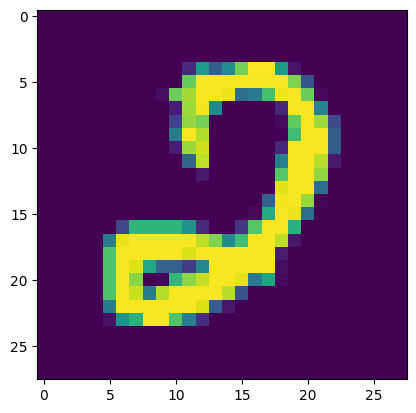

In [45]:
plt.imshow(X_test[400])

In [48]:
np.argmax(y_pred[400])

np.int64(2)

## =============================================================

## FINAL POINT: Let's Test for Outside new data

### Sepy 1: Let's Take out the model intelligence file 

In [50]:
model.save("digits_intel.h5")

### Step 2: Image Load 

In [73]:
from PIL import Image
img_path = r"C:\Users\SivaPrakash\Downloads\eight.png"
image = Image.open(img_path)
image = image.convert(mode = "L")
image = image.resize(size = (28,28))
image.size

(28, 28)

In [74]:
img_path = r"C:\Users\SivaPrakash\Downloads\eight.png"
image = Image.open(img_path).convert(mode = "L").resize((28,28))
image = np.array(image)
image

array([[255, 252, 236, 242, 255, 247, 236, 249, 255, 245, 232, 238, 235,
        218, 218, 235, 238, 232, 246, 255, 248, 235, 247, 255, 242, 236,
        252, 255],
       [244, 244, 247, 246, 244, 249, 246, 226, 204, 187, 180, 180, 180,
        179, 180, 180, 180, 177, 184, 206, 235, 251, 248, 243, 246, 247,
        244, 244],
       [240, 242, 251, 250, 239, 207, 182, 177, 185, 194, 202, 210, 216,
        204, 199, 199, 199, 198, 191, 164, 146, 182, 227, 243, 248, 251,
        242, 240],
       [254, 251, 239, 231, 180, 178, 193, 203, 221, 239, 246, 245, 241,
        211, 196, 198, 198, 198, 198, 201, 176, 138, 139, 212, 246, 237,
        251, 254],
       [240, 244, 242, 170, 187, 199, 218, 247, 242, 222, 207, 200, 197,
        197, 198, 198, 198, 198, 198, 198, 199, 165, 142, 135, 220, 252,
        242, 240],
       [243, 247, 187, 183, 198, 226, 252, 217, 197, 195, 197, 199, 198,
        199, 200, 198, 197, 198, 198, 198, 199, 187, 147, 141, 156, 246,
        244, 243],
       [25

In [75]:
predict_image(image)

(1, 28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


np.int64(3)

### Step 3: Let's do the Prediction

In [76]:
from keras.models import load_model
digits_brain = load_model("digits_intel.h5")

In [77]:
def predict_image(image):
    image = image/255.0
    image = np.expand_dims(a = image, axis = 0)
    print(image.shape)
    prediction = digits_brain.predict(image)
    return np.argmax(prediction)

In [78]:
predict_image(image)

(1, 28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


np.int64(3)

## THE END!!!